# CA4 - Telecom Customer Churn Classification

#### Gr 30: Sondre Aasheim & Zuzanna Magdalena Smolinska

### Imports

In [ ]:
import numpy as np                      # for numerical operations
import pandas as pd                     # for reading the csv files and working with dataframes
import matplotlib.pyplot as plt         # for basic plotting
import seaborn as sns                   # for more advanced plotting

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

### Rules and context of the Competition

(1) The general workflow is similar to that of CA3. As opposed to CA3, however, you are now expected to use cross-validation instead of multiple train/validation splits. You can use the scikit-learn implementations for cross-validation.

(2) You have access to a range of classifiers, kernels, and L1/L2-regularisation covered in DAT200. These can be combined freely. You can also use the ensemble models presented in the lectures. Use the corresponding scikit-learn implementations.

(3) Classifier selection and hyperparameter tuning are the core of this exercise. You are expected to make use of all of the following components:

   - Hyperparameter tuning (using scikit-learn tools from Chapter 6)
   - Scikit-learn Pipelines
   - Cross-validation
   - Some form of dimension reduction (e.g. PCA or SFS)
   - A confusion matrix for your final classifier, using a 60/40 train-test split on the entire training dataset
   - Macro-averaged F1-score as the primary evaluation metric (other metrics are encouraged too)

   You must build at least two pipelines combining preprocessing with a classifier. One pipeline must use a kernel, one must use regularisation, and at least one must include a dimension reduction step.

(4) You may try other models. If your best-performing Kaggle submission is not one of the two mandatory pipelines, also provide the code for training, tuning, and prediction for that classifier.

(5) You may engineer new features if you wish.

(6) If you are unsure how to structure your notebook, follow these steps:

Imports → Read the data → Data exploration & visualisation → Data cleaning → Data exploration & visualisation after cleaning → Preprocessing → Evaluating models/hyperparameters (cross-validation) → Kaggle submission.


### Reading the data

In [5]:
"""
Reading the data -
both files must be in the same folder as this notebook
"""

telecom_customer_train = pd.read_csv("trainCA4DAT200.csv")
telecom_customer_test = pd.read_csv("testCA4DAT200.csv")


### Data description

The dataset contains information about the customers of a mobile phone operator. Each row is one customer. The features are:

   - CustomerId – unique ID of the customer (not a feature for modelling)
   - State – US state where the customer lives (two-letter code)
   - AccountLength – how long the customer has had an account
   - AreaCode – telephone area code of the customer
   - InternationalPlan – whether the customer has an international calling plan (yes/no)
   - VoiceMailPlan – whether the customer has a voice mail plan (yes/no)
   - NumVoiceMailMessages – number of voice mail messages
   - DayMinutes, DayCalls, DayCharge – total minutes, number of calls and total charge for daytime calls
   - EveMinutes, EveCalls, EveCharge – the same for evening calls
   - NightMinutes, NightCalls, NightCharge – the same for night calls
   - IntlMinutes, IntlCalls, IntlCharge – the same for international calls
   - CustomerServiceCalls – number of calls the customer has made to customer service

Target variable: Churn
   - 0 = customer stays
   - 1 = customer leaves the company

### Data exploration & visualisation

In [ ]:
# printing the size of each dataset
print("train file shape:", telecom_customer_train.shape)
print("test file shape: ", telecom_customer_test.shape)


train file shape: (3500, 21)
test file shape:  (1500, 20)


We can see that the numbers match the assignment description, which confirms we loaded the right files

In [57]:
# printing the first 5 rows of the train dataset to get a look at the dataframe  
telecom_customer_train.head()


,CustomerId,State,AccountLength,AreaCode,InternationalPlan,VoiceMailPlan,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,...,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls,Churn
0,952920,NJ,87,510,no,no,0,223.2,109,37.94,...,86,10.84,289.3,83,13.02,14.5,4,3.92,3,0
1,895150,RI,114,510,no,yes,28,225.8,94,38.39,...,117,16.41,232.4,100,10.46,8.4,9,2.27,4,0
2,636987,ND,55,415,no,no,0,180.1,77,30.62,...,98,20.02,169.4,104,7.62,11.1,2,3.00,0,0
3,538188,DC,100,510,yes,no,0,68.5,110,11.65,...,115,28.65,205.2,99,9.23,12.1,9,3.27,0,0
4,947531,AL,74,408,no,yes,46,277.7,109,47.21,...,114,22.95,165.3,82,7.44,10.4,2,2.81,1,0


In [ ]:
# printing summary statistics for every numeric column, to get an overall view over the data, 
# had to keep it separate from the "head" command
telecom_customer_train.describe()


,CustomerId,AccountLength,AreaCode,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,EveMinutes,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls,Churn
count,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000
mean,545925.360857,99.996571,436.915429,8.112000,180.292429,100.016286,30.650306,200.763000,100.178000,17.065066,199.984857,99.669714,8.999397,10.297714,4.417143,2.780829,1.567714,0.141429
std,261478.546087,39.471509,42.169180,13.728371,53.764503,19.852587,9.139923,50.561814,19.800506,4.297740,50.132089,20.064302,2.256017,2.719716,2.456653,0.734263,1.298641,0.348513
min,101267.000000,1.000000,408.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,322381.000000,73.000000,415.000000,0.000000,143.700000,87.000000,24.430000,165.900000,87.000000,14.100000,166.700000,86.000000,7.500000,8.600000,3.000000,2.320000,1.000000,0.000000
50%,536375.500000,100.000000,415.000000,0.000000,179.700000,100.000000,30.550000,201.050000,100.000000,17.090000,199.700000,100.000000,8.990000,10.400000,4.000000,2.810000,1.000000,0.000000
75%,775246.750000,126.000000,415.000000,19.000000,216.525000,113.000000,36.812500,235.225000,113.000000,19.992500,233.625000,113.000000,10.512500,12.000000,6.000000,3.240000,2.000000,0.000000
max,999391.000000,243.000000,510.000000,52.000000,351.500000,163.000000,59.760000,361.800000,170.000000,30.750000,395.000000,175.000000,17.770000,20.000000,19.000000,5.400000,9.000000,1.000000


In [92]:
# printing the number and share of customers who stay (0) and leave (1)
counts = telecom_customer_train["Churn"].value_counts()
shares = telecom_customer_train["Churn"].value_counts(normalize=True)

print("The number of customers who stay: ", counts[0])
print("The number of customers who leave:", counts[1])
print()
print("The share of customers who stay: ", shares[0])
print("The share of customers who leave:", shares[1])


The number of customers who stay:  3005
The number of customers who leave: 495

The share of customers who stay:  0.8585714285714285
The share of customers who leave: 0.14142857142857143


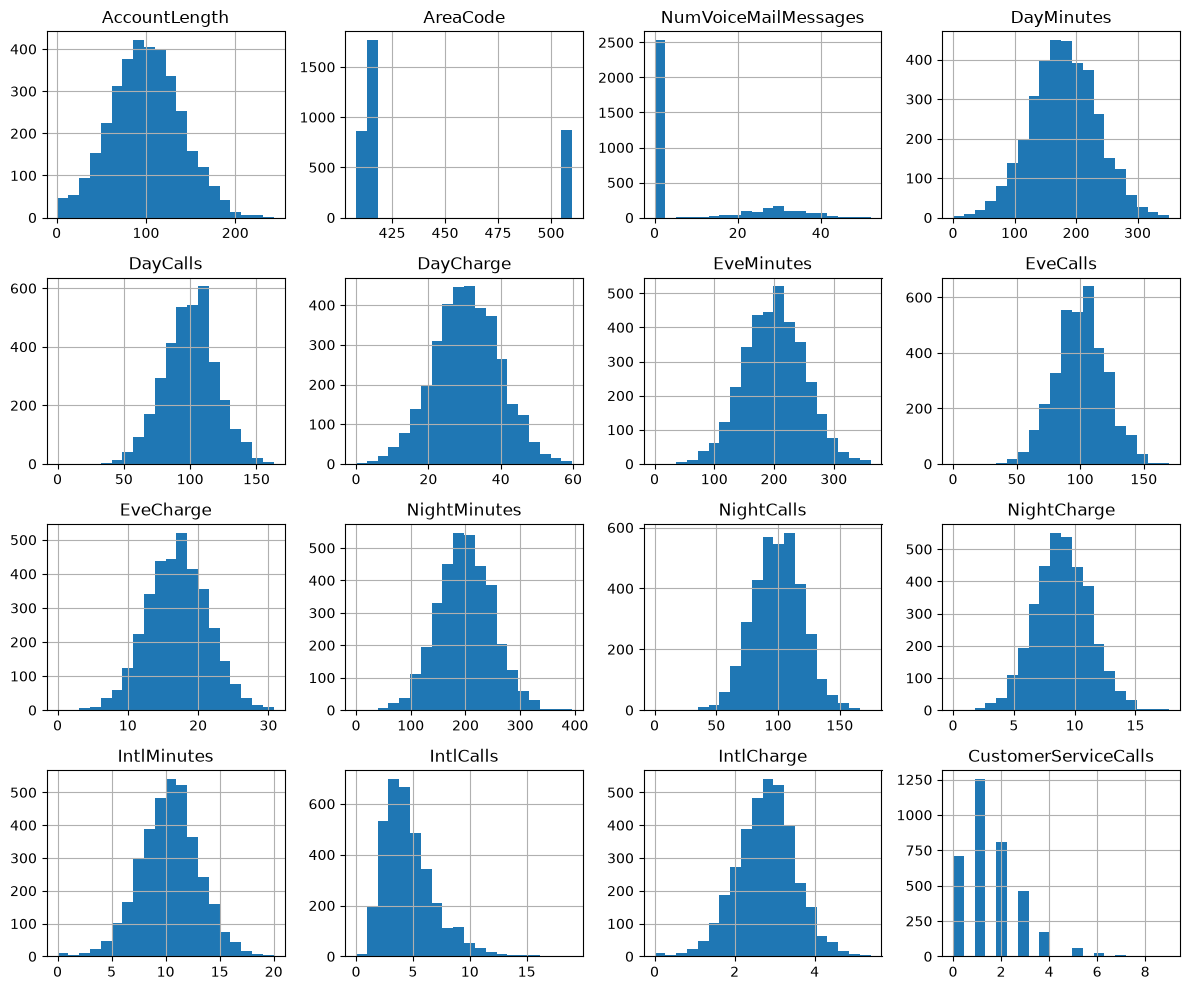

In [113]:
# histograms of all numeric features to see how the values are distributed
# CustomerId and Churn are left out, since they are not features

telecom_customer_train.drop(columns=["CustomerId", "Churn"]).hist(figsize=(12, 10), bins=20)
plt.tight_layout()          # adjusts spacing so the titles and axes don't overlap
plt.show()


**Discussion:**

- Most usage features and AccountLength are roughly normally distributed, without extreme values
- The -Minutes and -Charge histograms have the same shape for each period, which suggests that Charge is calculated directly from Minutes
- IntlCalls and CustomerServiceCalls are right-skewed: most customers have few calls, but a small group has many
- The features are on very different scales, so the data would need to be scaled before using any scale-sensitive models

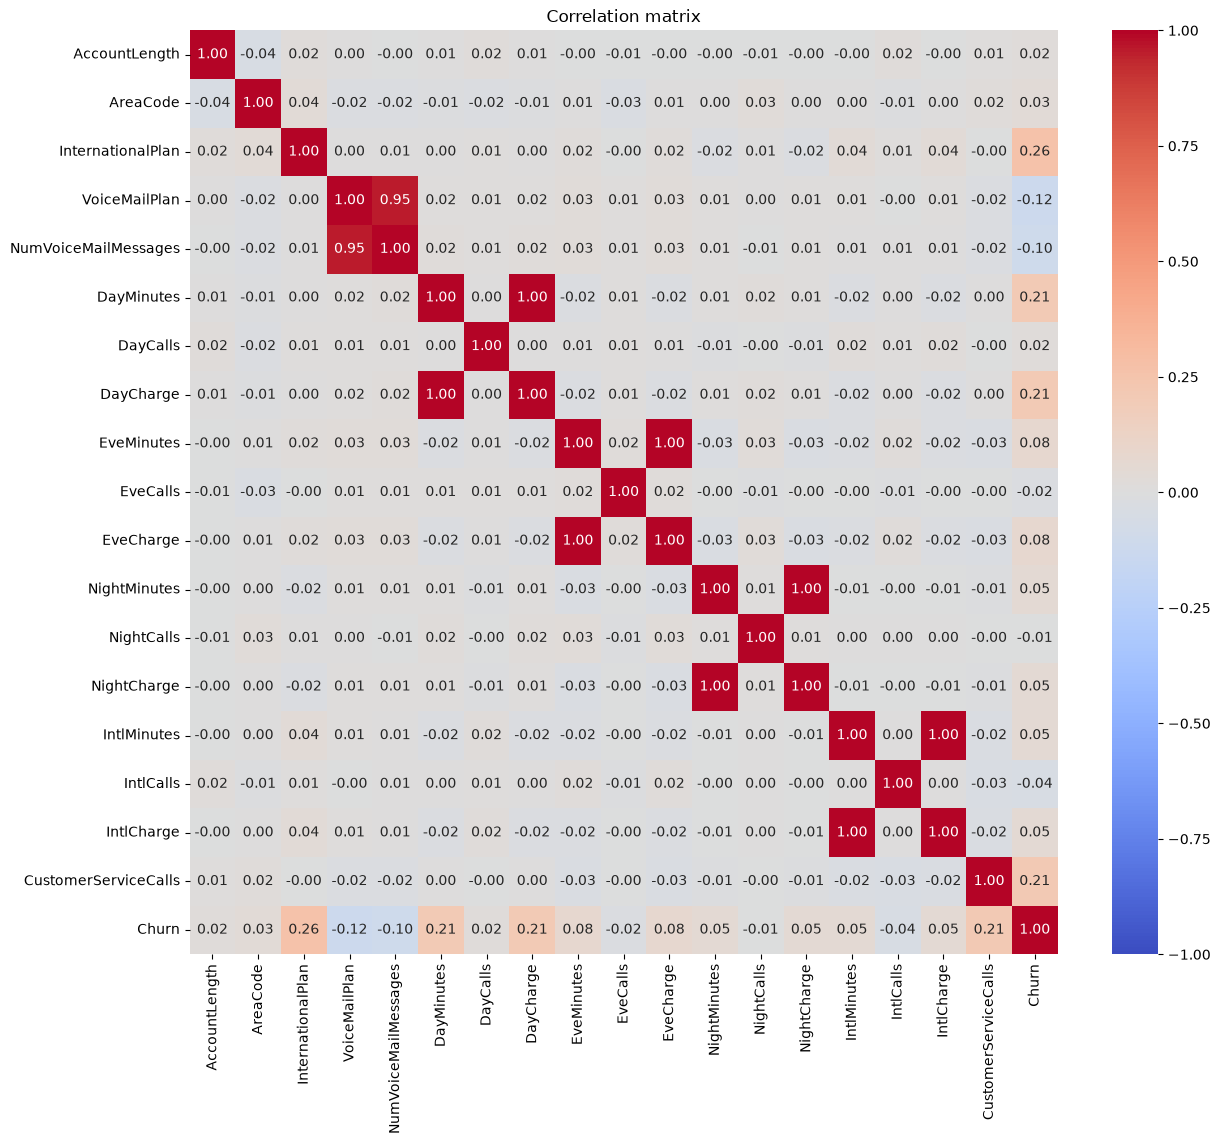

In [123]:
"""
We build correlation matrix: how strongly the features are related to each other and to Churn.
CustomerId (just an ID) and State (text with 51 values) are left out.

We make a separate copy of the data just for this plot.
Correlation only works on numbers, so we turn "yes"/"no" into 1/0 so that the -Plans can be included.
"""
corr_data = telecom_customer_train.drop(columns=["CustomerId", "State"]).copy()
corr_data["InternationalPlan"] = (corr_data["InternationalPlan"] == "yes").astype(int)
corr_data["VoiceMailPlan"] = (corr_data["VoiceMailPlan"] == "yes").astype(int)

corr = corr_data.corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()


**Discussion:**

- Each -Minutes -Charge pair has a correlation of 1.00, confirming that Charge is calculated directly from Minutes, so one of each pair is redundant
- VoiceMailPlan and NumVoiceMailMessages are also strongly correlated (0.95)
- Apart from these pairs, the features are almost uncorrelated with each other (values close to 0)
- The features most related to Churn are InternationalPlan (0.26), CustomerServiceCalls (0.21) and DayMinutes/DayCharge (0.21)
- VoiceMailPlan is slightly negative (-0.12), meaning customers with a voice mail plan churn somewhat less
- All correlations with Churn are fairly weak

### Data cleaning 

In [133]:
# counting all missing values in the training and test data
# this should give 0, if there are no missing numbers or information
# (meaning we don't need to look into this any deeper)

print(telecom_customer_train.isna().sum().sum())
print(telecom_customer_test.isna().sum().sum())

0
0


In [135]:
# checking for outliers the numeric features
# CustomerId, AreaCode and Churn are left out, as they are not real measurements
numeric_features = ["AccountLength", "NumVoiceMailMessages", "DayMinutes", "DayCalls", "DayCharge", "EveMinutes", "EveCalls", "EveCharge", "NightMinutes", "NightCalls", "NightCharge", "IntlMinutes", "IntlCalls", "IntlCharge", "CustomerServiceCalls"]

# z = (x - mean) / std: how many standard deviations each value is from the mean
z_scores = (telecom_customer_train[numeric_features] - telecom_customer_train[numeric_features].mean()) /telecom_customer_train[numeric_features].std(ddof=0)

# checking if the z score is above or under the average by 5 through using absolute values
# we use a threshold of 5 instead of the usual 3, as phone usage can vary a lot between customers
outliers = z_scores.abs() > 5

# showing only the features that do have outliers
print("Outliers per feature:")
print(outliers.sum()[outliers.sum() > 0])


Outliers per feature:
DayCalls                1
EveCalls                1
IntlCalls               7
CustomerServiceCalls    2
dtype: int64


In [137]:
# checking the rows with at least one outlier, and whether these customers churned
outlier_rows = outliers.any(axis=1)

print("Rows with at least one outlier:", outlier_rows.sum(), "of", len(telecom_customer_train))


Rows with at least one outlier: 11 of 3500


In [139]:
# showing the rows with at least one outlier
telecom_customer_train.loc[outlier_rows, ["DayCalls", "EveCalls", "IntlCalls", "CustomerServiceCalls", "Churn"]]


,DayCalls,EveCalls,IntlCalls,CustomerServiceCalls,Churn
57,106,101,18,1,0
544,0,119,4,1,0
693,123,108,18,1,0
772,107,89,18,2,1
1198,91,107,17,2,0
2411,134,0,6,1,0
2622,118,82,17,0,0
2645,120,94,3,9,1
2785,117,123,2,9,1
2978,110,65,19,3,0


**Discussion:**

Only 11 of 3500 customers have an extreme value (|z| > 5). These are not measurement errors but realistic customers, such as people who make many international calls or call customer service 9 times. Both customers with 9 service calls churned, so these rows carry important information about churn. We also cannot remove outliers from the test set, so the model must be able to handle such values anyway. We therefore keep all rows.

### Data exploration & visualisation after cleaning

**Conclusion of data cleaning:**

The dataset has no missing values, and the few extreme values are realistic customers rather than errors, so no rows were removed. The data is therefore used as it is, and the necessary transformations will be done in the preprocessing step.

### Preprocessing

In the preprocessing part, we prepare the data for the models:
- drop columns that are not useful features (CustomerId, State)
- convert text categories into numbers
- create new features
- create the feature matrix X, the target y and the Kaggle test features X_test

Scaling and dimension reduction (PCA) are not done here. Instead, they are part of the pipelines in the modelling section, so they are fitted only on the training part of each cross-validation fold.

Both steps learn from the data - the scaler computes the mean and standard deviation, while PCA finds the directions of largest variance. If we fitted them on the whole training set before cross-validation, they would also learn from the validation folds, so information from the "unseen" data would leak into the training and give too optimistic scores (data leakage). 

In [ ]:
def preprocess(df):
    # preparing a dataframe (train or test) for modelling

    # working on a copy of the dataframe so that the original data stays unchanged
    df = df.copy()

    # removing columns that are not useful for modelling
    # CustomerId is only an ID, and State has 51 categories with no clear relation to churn
    df = df.drop(columns=["CustomerId", "State"])

    # converting yes/no columns to numbers (1/0)
    df["InternationalPlan"] = (df["InternationalPlan"] == "yes").astype(int)
    df["VoiceMailPlan"] = (df["VoiceMailPlan"] == "yes").astype(int)

    # AreaCode is a category, not a number, so we replace it with three new columns, one for each area code, with 0/1 values
    df = pd.get_dummies(df, columns=["AreaCode"], prefix="Area", dtype=int)

    # adding some new features that describe the customer's total usage over the whole day
    df["TotalMinutes"] = df["DayMinutes"] + df["EveMinutes"] + df["NightMinutes"] + df["IntlMinutes"]
    df["TotalCalls"] = df["DayCalls"] + df["EveCalls"] + df["NightCalls"] + df["IntlCalls"]
    df["TotalCharge"] = df["DayCharge"] + df["EveCharge"] + df["NightCharge"] + df["IntlCharge"]

    # returning the prepared dataframe
    return df

In [ ]:
"""
Preparing the data to be used for modelling:
- X:      the features of the training customers (everything except Churn)
- y:      the target we want to predict (0 = stays, 1 = leaves)
- X_test: the features of the Kaggle test customers, prepared in exactly the same way as X
"""

X = preprocess(telecom_customer_train.drop(columns=["Churn"]))
y = telecom_customer_train["Churn"]
X_test = preprocess(telecom_customer_test)

# checking the result: 
# X and X_test must have the same number of columns,
# X and y must have the same number of rows

print("X:     ", X.shape)
print("y:     ", y.shape)
print("X_test:", X_test.shape)

# the first rows of the prepared data
X.head()

### Evaluating models/hyperparameters (cross-validation)

### Kaggle submission



BACKGROUND

You have been hired by a mobile phone operator in the United States. The company is experiencing customer churn, where customers cancel their subscription and move to a competing operator. Retaining existing customers is often significantly cheaper than acquiring new ones.

Your task is to develop a machine learning model capable of predicting whether a customer will leave the company based on information about their subscription plan and phone usage. Accurate churn prediction models allow companies to identify customers who may leave and take proactive measures to retain them.

churn.png

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


KAGGLE COMPETITION

You will participate in an in-class Kaggle competition where you will compete with fellow students on how well your model predicts the test data.

1. Link to our in-class competition on Kaggle:
   DAT200 CA4 H2026: https://www.kaggle.com/competitions/dat-200-ca-4-h-2026/overview 

2. Enrolment link (do not forward this link to anyone outside DAT200):
   https://www.kaggle.com/t/57bfce3eeeb14253a4a1e02ce6e2a15f 

3. On the Data tab of the competition you will find three files:
   - trainCA4DAT200.csv – 3,500 customers, including the target column Churn
   - testCA4DAT200.csv – 1,500 customers, without the target column
   - sample_submissionCA4DAT200.csv – shows the required format of your submission

4. Notebook template: You can use the notebook template from the last compulsory assignment (CA3) to build your classification pipeline, or start from scratch. Note that CA3 used repeated train/validation splits and accuracy. In CA4 you must use cross-validation and macro F1 instead, so update the template's headings and code accordingly.

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


IMPORTANT NOTES

- It is your responsibility to upload your submission before the deadline to both Canvas and Kaggle. Plan for possible technical difficulties. You may submit multiple times — only the final submission counts.
- Complete the assignment as a group.
- If you copy a larger piece of code (multiple lines or a complex expression), cite the source with a link, mark the copied section, and explain what it does in your own words.
- Train and evaluate your models only on the data provided in this competition. Using any other version of this data, or labels from outside the competition, is not allowed and counts as cheating.
- Review the CA rules on the course pages. You must pass all CAs to be admitted to the exam.

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

DELIVERABLES / SUBMISSION

To have the compulsory assignment approved you need to deliver the following:

1. Data exploration and visualisation of the data is mandatory. Use several techniques to explore the data effectively.
2. Your name must appear on the leaderboard of our in-class Kaggle competition, meaning you must submit at least one prediction.
3. We expect you to beat the benchmark (named BEAT ME) on the public leaderboard.
   Evaluation metric: F1 macro score.
4. Submit the following files:
   - Jupyter notebook (.ipynb)
   - PDF export of the notebook
   - Python code (.py)
   Your submission must include a confusion matrix.
5. If you use an alias on Kaggle, provide both your alias and real name at the beginning of the notebook.